# 05 – Strategies, safety stock & reorder point, simulation, 10 articles

1. **Strategy per article** from the classification
2. **Safety stock & reorder point** – case study formula and a textbook comparison
3. **Backtest simulation** (evaluation): parameters from 2019–2020, replay real daily demand of 2021,
   compare current vs. new reorder points on fill rate, stockout days and capital lockup
4. **Total capital effect** per strategy
5. **10 selected articles** – detailed recommendation and figures
6. Export tables for the report appendix

**Output to share:** `outputs/tables/05_recommendation_summary.txt`

In [1]:
import sys, math
from collections import deque
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.insert(0, str(Path.cwd().parent))
from src import config as C

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight"})

summary = []
def log(title, obj=""):
    text = obj.to_string() if isinstance(obj, (pd.DataFrame, pd.Series)) else str(obj)
    block = f"\n=== {title} ===\n{text}"
    print(block)
    summary.append(block)

def savefig(name):
    plt.savefig(C.FIGURES / f"{name}.png")
    plt.show()

REF = pd.Timestamp(C.REFERENCE_DATE)
DPY, DPM = C.DAYS_PER_YEAR, C.DAYS_PER_MONTH

art = pd.read_parquet(C.ARTICLE_FEATURES).set_index("article_nr")
art = art.join(pd.read_parquet(C.ARTICLE_CLUSTERS).set_index("article_nr"))
dm = pd.read_parquet(C.DEMAND_MONTHLY)
tx = pd.read_parquet(C.TRANSACTIONS_CLEAN)
price = art["last_direct_cost"]
total_lockup = art["lockup_12m"].sum()
log("Loaded", f"{len(art):,} articles | clusters: {art['cluster'].value_counts().sort_index().to_dict()}")


=== Loaded ===
1,751 articles | clusters: {'C1': 743, 'C2': 474, 'C3': 281, 'ND (no demand)': 253}


## 1. Strategy per article

| Class | Strategy |
|---|---|
| C1 production components | **Stock – optimised** SS/ROP |
| C2 retail (and the few semi-finished) | **Stock – optimised** SS/ROP |
| C2 finished products | **Make-to-order** (can be produced quickly on site – no stock) |
| C3 sporadic slow movers | **Order on demand** – no stock, stop reordering, sell down |
| ND, article older than 1 year | **Phase out** – no reorder, sell down / write off |
| ND, article younger than 1 year | **Observe** – keep current settings |

In [2]:
age_years = art["age_days"] / 365
art["strategy"] = np.select(
    [art["cluster"].isin(["C1"]),
     (art["cluster"] == "C2") & (art["product_type"] == "finished"),
     art["cluster"] == "C2",
     art["cluster"] == "C3",
     art["cluster"].str.startswith("ND") & (age_years < 1)],
    ["stock – optimised", "make-to-order", "stock – optimised", "order on demand", "observe (new)"],
    default="phase out")

st = art.groupby(["cluster", "strategy"]).agg(articles=("lockup_12m", "size"), lockup=("lockup_12m", "sum"))
st["lockup_share_%"] = (st["lockup"] / total_lockup * 100).round(1)
log("Strategy by class", st.round(0))
stocked = art["strategy"] == "stock – optimised"


=== Strategy by class ===
                                  articles     lockup  lockup_share_%
cluster        strategy                                              
C1             stock – optimised       743  2649593.0            53.0
C2             make-to-order           210   227093.0             5.0
               stock – optimised       264  1701318.0            34.0
C3             order on demand         281   234926.0             5.0
ND (no demand) observe (new)            71    56334.0             1.0
               phase out               182    88992.0             2.0


## 2. Safety stock & reorder point

**Case study formula**
- SS = standard deviation of (monthly) demand
- ROP = (annual demand / 360) × lead time + SS
- No lead time maintained → SS = usage of the last 12 months / 4, ROP = SS

**Textbook comparison** (service-level based, accounts for lead time)
- SS = z × σ_month × √(lead time / 30), z by ABC class (A 98%, B 95%, C 90%)
- ROP = daily demand × lead time + SS

Order quantity Q (needed for stock levels and simulation) = max(MOQ, one month of demand).
Expected average stock ≈ SS + Q/2.

Demand statistics use outlier-capped monthly demand. Note: the company's `safety_stock` field **is** its reorder point.

In [3]:
def sizing(stats, art_, zmap=None):
    """stats: DataFrame with mean_m, std_m, usage12 per article -> SS/ROP/Q for both methods."""
    s = stats.reindex(art_.index).fillna(0).join(art_[["lead_time", "moq", "abc"]])  # all articles, 0 if no history
    d = s["mean_m"] * 12 / DPY                      # daily demand (360-day year, as in the case formula)
    lt = s["lead_time"]
    no_lt = lt <= 0
    out = pd.DataFrame(index=s.index)
    out["ss_case"] = np.where(no_lt, s["usage12"] / 4, s["std_m"])
    out["rop_case"] = np.where(no_lt, out["ss_case"], d * lt + out["ss_case"])
    zmap = zmap or C.SERVICE_Z
    z = s["abc"].map(zmap).fillna(zmap["C"])
    lt_eff = np.where(no_lt, DPM, lt)                # no lead time -> assume 30 days for the textbook variant
    out["ss_textbook"] = z * s["std_m"] * np.sqrt(lt_eff / DPM)
    out["rop_textbook"] = d * lt_eff + out["ss_textbook"]
    out["q"] = np.maximum(s["moq"], s["mean_m"])
    return out.fillna(0)

def demand_stats(dm_, until=None):
    x = dm_ if until is None else dm_[dm_["month"] <= until]
    x = x.dropna(subset=["demand_capped"])
    g = x.groupby("article_nr")["demand_capped"]
    last12 = x[x["month"] > x["month"].max() - pd.DateOffset(months=12)].groupby("article_nr")["demand_capped"].sum()
    return pd.DataFrame({"mean_m": g.mean(), "std_m": g.std(), "usage12": last12}).fillna(0)

# Final recommendation: all data 2019-2021
rec = sizing(demand_stats(dm), art)
art = art.join(rec)
art["current_rop"] = art["safety_stock"]
for m in ("case", "textbook"):
    art[f"exp_lockup_{m}"] = (art[f"ss_{m}"] + art["q"] / 2) * price
art["exp_lockup_q1m_case"] = (art["ss_case"] + art["mean_monthly"].fillna(0) / 2) * price  # if order size = 1 month

s = art[stocked]
comp = pd.DataFrame({
    "current ROP (sum of value)": [(s["current_rop"] * price[s.index]).sum()] * 2,
    "new ROP (sum of value)": [(s["rop_case"] * price[s.index]).sum(), (s["rop_textbook"] * price[s.index]).sum()],
    "articles ROP lower": [(s["rop_case"] < s["current_rop"]).sum(), (s["rop_textbook"] < s["current_rop"]).sum()],
    "articles ROP higher": [(s["rop_case"] > s["current_rop"]).sum(), (s["rop_textbook"] > s["current_rop"]).sum()],
}, index=["case formula", "textbook"])
log("Stocked articles – current vs. new reorder points", comp.round(0))


=== Stocked articles – current vs. new reorder points ===
              current ROP (sum of value)  new ROP (sum of value)  articles ROP lower  articles ROP higher
case formula                   1976530.0               2420080.0                 570                  437
textbook                       1976530.0               3649433.0                 526                  481


## 3. Backtest simulation (evaluation)
For every stocked article: daily demand of 2021 is replayed (2020 as warm-up). Continuous review:
when inventory position ≤ ROP, order Q (multiples if needed), arriving after the lead time. Unmet demand is lost.
Policies are sized with data from **2019–2020 only** (out-of-sample). Same Q for all policies, so differences come
from the reorder point alone.

Metrics: **fill rate** (share of demand served from stock), **stockout days** (days with unmet demand / days with demand),
**average stock value** in 2021.


=== Backtest coverage ===
925 of 1007 stocked articles simulated (skipped: no demand in 2019-2020 or none in 2020-2021)

=== Backtest 2021 – all stocked articles ===
          articles  fill rate (value-weighted)  fill rate (median article)  stockout days / demand days  avg stock value 2021  stock value vs current %
policy                                                                                                                                                 
current      925.0                       0.740                       0.994                        0.120           1779803.731                     0.000
case         925.0                       0.879                       0.973                        0.065           1990100.852                    11.816
textbook     925.0                       0.942                       1.000                        0.044           3069187.736                    72.445

=== Backtest by ABC class (value-weighted fill rate, stock value) ===
  

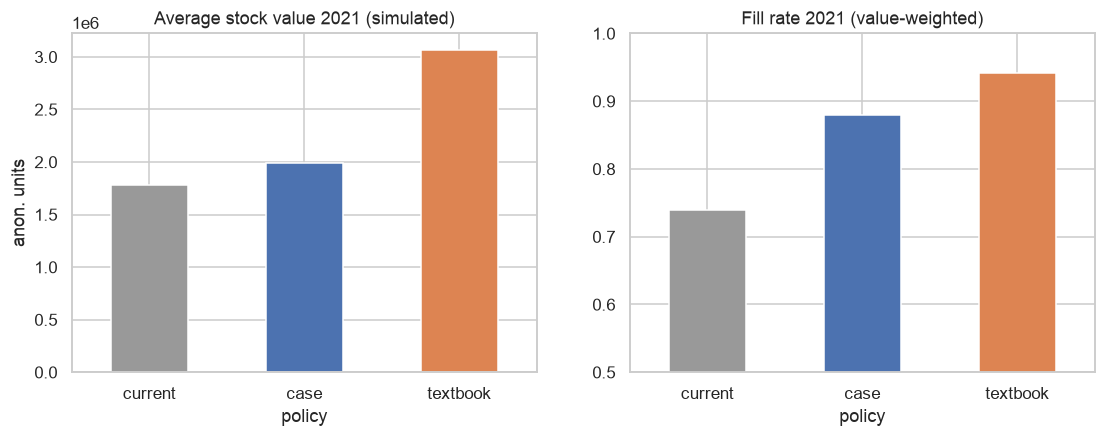

In [4]:
w0, s0, s1 = pd.Timestamp(C.SIM_WARMUP_START), pd.Timestamp(C.SIM_START), pd.Timestamp(C.SIM_END)
days = pd.date_range(w0, s1, freq="D")
meas = days >= s0

dd = tx[(tx["entry_type"].isin(C.DEMAND_TYPES)) & tx["date"].between(w0, s1)]
dd = dd.groupby(["article_nr", "date"])["demand"].sum().clip(lower=0)
daily = dd.unstack("date").reindex(columns=days).fillna(0)

stats_bt = demand_stats(dm, until=pd.Timestamp(C.PARAM_END))
par = sizing(stats_bt, art)
has_hist = set(stats_bt.index[stats_bt["mean_m"] > 0])   # articles with demand in 2019-2020
lt_sim = art["lead_time"].where(art["lead_time"] > 0,
                                art.groupby("item_main_group")["lead_time"].transform(lambda x: x[x > 0].median())).fillna(30)

def simulate(d, rop, q, lt):
    lt = max(int(round(lt)), 1)
    on_hand, pipe = rop + q / 2, deque()
    pending = 0.0
    stock = np.empty(len(d)); unmet = np.zeros(len(d))
    for t, dem in enumerate(d):
        while pipe and pipe[0][0] == t:
            _, qty = pipe.popleft(); on_hand += qty; pending -= qty
        served = min(on_hand, dem); on_hand -= served; unmet[t] = dem - served
        pos = on_hand + pending
        if q > 0 and pos <= rop:
            k = math.floor((rop - pos) / q) + 1
            pipe.append((t + lt, k * q)); pending += k * q
        stock[t] = on_hand
    return stock, unmet

res = []
ids = [a for a in art.index[stocked] if a in daily.index and a in has_hist]
log("Backtest coverage", f"{len(ids)} of {stocked.sum()} stocked articles simulated "
                         f"(skipped: no demand in 2019-2020 or none in 2020-2021)")
for a in ids:
    d = daily.loc[a].values
    q = par.at[a, "q"]
    if q <= 0:
        continue
    for pol, rop in (("current", art.at[a, "current_rop"]), ("case", par.at[a, "rop_case"]),
                     ("textbook", par.at[a, "rop_textbook"])):
        stock, unmet = simulate(d, rop, q, lt_sim[a])
        dm_ = d[meas]; um = unmet[meas]
        res.append({"article_nr": a, "policy": pol, "demand": dm_.sum(), "unmet": um.sum(),
                    "demand_days": (dm_ > 0).sum(), "stockout_days": (um > 1e-9).sum(),
                    "avg_stock_value": stock[meas].mean() * price[a]})
sim = pd.DataFrame(res)
sim["fill_rate"] = 1 - sim["unmet"] / sim["demand"].replace(0, np.nan)
sim["demand_value"] = sim["demand"] * sim["article_nr"].map(price)

agg = sim.groupby("policy").apply(lambda g: pd.Series({
    "articles": g["article_nr"].nunique(),
    "fill rate (value-weighted)": 1 - (g["unmet"] * g["article_nr"].map(price)).sum() / g["demand_value"].sum(),
    "fill rate (median article)": g["fill_rate"].median(),
    "stockout days / demand days": g["stockout_days"].sum() / g["demand_days"].sum(),
    "avg stock value 2021": g["avg_stock_value"].sum(),
})).reindex(["current", "case", "textbook"])
agg["stock value vs current %"] = (agg["avg stock value 2021"] / agg.loc["current", "avg stock value 2021"] * 100 - 100)
log("Backtest 2021 – all stocked articles", agg.round(3))

simc = sim.merge(art[["abc", "cluster"]], left_on="article_nr", right_index=True)
by_abc = simc.groupby(["abc", "policy"]).apply(
    lambda g: pd.Series({"fill_rate_w": 1 - (g["unmet"] * g["article_nr"].map(price)).sum() / g["demand_value"].sum(),
                         "stock_value": g["avg_stock_value"].sum()})).unstack("policy")
log("Backtest by ABC class (value-weighted fill rate, stock value)", by_abc.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
agg["avg stock value 2021"].plot.bar(ax=axes[0], color=["#999999", "#4C72B0", "#DD8452"])
axes[0].set_title("Average stock value 2021 (simulated)"); axes[0].set_ylabel("anon. units"); axes[0].tick_params(axis="x", rotation=0)
agg["fill rate (value-weighted)"].plot.bar(ax=axes[1], color=["#999999", "#4C72B0", "#DD8452"])
axes[1].set_ylim(0.5, 1); axes[1].set_title("Fill rate 2021 (value-weighted)"); axes[1].tick_params(axis="x", rotation=0)
savefig("05_backtest_policies")

### Efficiency frontier – which service level?
The textbook formula is simulated with several service-level settings. Each setting gives one point
(capital vs. fill rate); current policy and case formula are shown for reference.
**Selection rule:** the lowest-capital setting with a value-weighted fill rate of at least `TARGET_FILL`.


=== Efficiency frontier (textbook formula, backtest 2021) ===
                 fill_rate_w  stock_value
setting                                  
uniform 85%            0.890  2212126.568
A90 / B85 / C80        0.900  2377335.624
uniform 90%            0.903  2445004.522
A95 / B90 / C85        0.922  2690760.379
uniform 95%            0.926  2788362.705
A98 / B95 / C90        0.942  3069187.736
A99 / B95 / C90        0.950  3290116.633

=== Reference points ===
         fill_rate_w  stock_value
current        0.740  1779803.731
case           0.879  1990100.852

=== Chosen service-level setting (target fill rate 90%) ===
A90 / B85 / C80  {'A': 1.28, 'B': 1.04, 'C': 0.84}


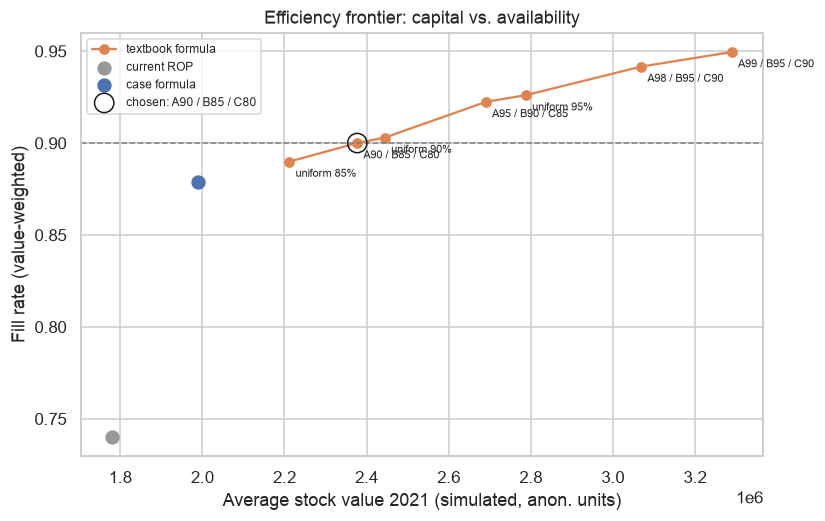

In [5]:
TARGET_FILL = 0.90
SL_SETS = {   # z-values for A / B / C
    "uniform 85%":       {"A": 1.04, "B": 1.04, "C": 1.04},
    "uniform 90%":       {"A": 1.28, "B": 1.28, "C": 1.28},
    "A90 / B85 / C80":   {"A": 1.28, "B": 1.04, "C": 0.84},
    "A95 / B90 / C85":   {"A": 1.65, "B": 1.28, "C": 1.04},
    "uniform 95%":       {"A": 1.65, "B": 1.65, "C": 1.65},
    "A98 / B95 / C90":   {"A": 2.05, "B": 1.65, "C": 1.28},
    "A99 / B95 / C90":   {"A": 2.33, "B": 1.65, "C": 1.28},
}

def run_policy(rops):
    out = []
    for a in ids:
        q = par.at[a, "q"]
        if q <= 0:
            continue
        stock, unmet = simulate(daily.loc[a].values, rops[a], q, lt_sim[a])
        d = daily.loc[a].values[meas]
        out.append({"article_nr": a, "demand": d.sum(), "unmet": unmet[meas].sum(),
                    "demand_days": (d > 0).sum(), "stockout_days": (unmet[meas] > 1e-9).sum(),
                    "avg_stock_value": stock[meas].mean() * price[a]})
    return pd.DataFrame(out)

def kpis(df_):
    v = df_["article_nr"].map(price)
    return {"fill_rate_w": 1 - (df_["unmet"] * v).sum() / (df_["demand"] * v).sum(),
            "stock_value": df_["avg_stock_value"].sum()}

frontier, sims_by_set = [], {}
for name, z in SL_SETS.items():
    r = run_policy(sizing(stats_bt, art, zmap=z)["rop_textbook"])
    sims_by_set[name] = r
    frontier.append({"setting": name, **kpis(r)})
frontier = pd.DataFrame(frontier).set_index("setting").sort_values("stock_value")
ref = pd.DataFrame({p_: kpis(sim[sim["policy"] == p_]) for p_ in ["current", "case"]}).T
log("Efficiency frontier (textbook formula, backtest 2021)", frontier.round(3))
log("Reference points", ref.round(3))

ok = frontier[frontier["fill_rate_w"] >= TARGET_FILL]
CHOSEN = ok["stock_value"].idxmin() if len(ok) else frontier["fill_rate_w"].idxmax()
CHOSEN_Z = SL_SETS[CHOSEN]
log(f"Chosen service-level setting (target fill rate {TARGET_FILL:.0%})", f"{CHOSEN}  {CHOSEN_Z}")

plt.figure(figsize=(8, 5))
plt.plot(frontier["stock_value"], frontier["fill_rate_w"], "o-", color="#DD8452", label="textbook formula")
for n_, r_ in frontier.iterrows():
    plt.annotate(n_, (r_["stock_value"], r_["fill_rate_w"]), fontsize=7, xytext=(4, -10), textcoords="offset points")
for n_, r_, c_ in (("current ROP", ref.loc["current"], "#999999"), ("case formula", ref.loc["case"], "#4C72B0")):
    plt.scatter(r_["stock_value"], r_["fill_rate_w"], s=70, color=c_, zorder=3, label=n_)
plt.scatter(frontier.loc[CHOSEN, "stock_value"], frontier.loc[CHOSEN, "fill_rate_w"], s=160, facecolors="none",
            edgecolors="k", zorder=4, label=f"chosen: {CHOSEN}")
plt.axhline(TARGET_FILL, ls="--", c="grey", lw=1)
plt.xlabel("Average stock value 2021 (simulated, anon. units)"); plt.ylabel("Fill rate (value-weighted)")
plt.title("Efficiency frontier: capital vs. availability")
plt.legend(fontsize=8)
savefig("05_efficiency_frontier")

**Final method:** textbook formula with the chosen service levels. Recommendations use all data 2019–2021;
the backtest parameters (`par_final`) use 2019–2020 only.

In [6]:
METHOD = "textbook"
rec_final = sizing(demand_stats(dm), art, zmap=CHOSEN_Z)
art["ss_textbook"], art["rop_textbook"] = rec_final["ss_textbook"], rec_final["rop_textbook"]
art["exp_lockup_textbook"] = (art["ss_textbook"] + art["q"] / 2) * price
par_final = sizing(stats_bt, art, zmap=CHOSEN_Z)

final_sim = sims_by_set[CHOSEN].assign(policy="final")
sim = pd.concat([sim[sim["policy"] != "final"], final_sim.assign(
    fill_rate=1 - final_sim["unmet"] / final_sim["demand"].replace(0, np.nan),
    demand_value=final_sim["demand"] * final_sim["article_nr"].map(price))], ignore_index=True)

art["new_ss"] = np.where(stocked, art[f"ss_{METHOD}"], 0)
art["new_rop"] = np.where(stocked, art[f"rop_{METHOD}"], 0)
art.loc[art["strategy"] == "observe (new)", "new_rop"] = art["current_rop"]

act = art.loc[ids, "lockup_12m"].sum()
cur_sim = sim.loc[sim["policy"] == "current", "avg_stock_value"].sum()
log("Ordering behaviour vs. reorder-point policy (simulated articles)", pd.Series({
    "actual capital lockup (last 12 months)": round(act),
    "simulated: current ROP + disciplined order size": round(cur_sim),
    "share of capital beyond the ROP policy": f"{1 - cur_sim / act:.0%}",
}))
log("Final method", f"{METHOD} with {CHOSEN}")


=== Ordering behaviour vs. reorder-point policy (simulated articles) ===
actual capital lockup (last 12 months)             4104209
simulated: current ROP + disciplined order size    1779804
share of capital beyond the ROP policy                 57%

=== Final method ===
textbook with A90 / B85 / C80


## 4. Total capital effect per strategy
- Stocked articles: expected lockup = (new SS + Q/2) × price
- Make-to-order / order on demand / phase out: lockup → 0 once existing stock is consumed or sold (one-off effect)
- Observe (new): unchanged
- Extra lever: if order quantities were reduced to one month of demand (MOQ renegotiation)

In [7]:
art["new_lockup"] = np.select(
    [stocked, art["strategy"] == "observe (new)"],
    [art[f"exp_lockup_{METHOD}"], art["lockup_12m"]], default=0.0)

eff = art.groupby("strategy").agg(articles=("lockup_12m", "size"), current_lockup=("lockup_12m", "sum"),
                                  new_lockup=("new_lockup", "sum"))
eff.loc["TOTAL"] = eff.sum()
eff["change"] = eff["new_lockup"] - eff["current_lockup"]
eff["change_%"] = (eff["change"] / eff["current_lockup"] * 100).round(1)
log(f"Capital lockup effect ({METHOD})", eff.round(0))

s = art[stocked]
lever = pd.Series({
    "stocked: current lockup": s["lockup_12m"].sum(),
    "stocked: new SS/ROP, current order sizes": s[f"exp_lockup_{METHOD}"].sum(),
    "stocked: new SS/ROP + order size = 1 month demand": ((s[f"ss_{METHOD}"] + s["mean_monthly"].fillna(0) / 2) * price[s.index]).sum(),
})
log("Order-size lever for stocked articles", lever.round(0))


=== Capital lockup effect (textbook) ===
                   articles  current_lockup  new_lockup     change  change_%
strategy                                                                    
make-to-order         210.0        227093.0         0.0  -227093.0    -100.0
observe (new)          71.0         56334.0     56334.0        0.0       0.0
order on demand       281.0        234926.0         0.0  -234926.0    -100.0
phase out             182.0         88992.0         0.0   -88992.0    -100.0
stock – optimised    1007.0       4350912.0   2176240.0 -2174671.0     -50.0
TOTAL                1751.0       4958257.0   2232575.0 -2725683.0     -55.0

=== Order-size lever for stocked articles ===
stocked: current lockup                              4350912.0
stocked: new SS/ROP, current order sizes             2176240.0
stocked: new SS/ROP + order size = 1 month demand    1784903.0


## 5. Ten articles for the detailed recommendation
Chosen by the agreed criteria (each category picks the highest-capital article not yet chosen).
Override with `MANUAL` if you want specific articles.

In [8]:
MANUAL = []   # e.g. ["1425485", "1324850", ...]

enough = art["months_observed"].fillna(0) >= 24
chosen, reason = [], {}
def pick(mask, why, key="lockup_12m", ascending=False):
    c = art[mask & ~art.index.isin(chosen)].sort_values(key, ascending=ascending)
    if len(c):
        chosen.append(c.index[0]); reason[c.index[0]] = why

if MANUAL:
    chosen = [str(a) for a in MANUAL]; reason = {a: "manual" for a in chosen}
else:
    pick(stocked & (art["cluster"] == "C1") & enough, "C1 – highest capital lockup")
    pick(stocked & (art["cluster"] == "C2") & enough, "C2 retail – highest capital lockup")
    pick(stocked & (art["moq_months"] > 12) & enough, "MOQ-driven stock (one order > 12 months of demand)")
    pick(stocked & (art["pattern"] == "smooth") & enough, "steady (smooth) demand")
    pick(stocked & art["pattern"].isin(["lumpy", "intermittent"]) & enough, "lumpy / searched demand")
    pick(stocked & (art["rop_ratio"] > 10) & enough, "heavily oversized reorder point (> 10x lead-time demand)")
    pick(stocked & (art["lead_time"] == 0), "no lead time maintained (fallback formula)")
    pick(art["strategy"] == "make-to-order", "finished product → make-to-order")
    pick(art["strategy"] == "order on demand", "C3 sporadic → order on demand")
    pick(art["strategy"] == "phase out", "no demand → phase out")

cols = ["cluster", "strategy", "product_type", "abc", "xyz", "pattern", "last_direct_cost", "lead_time", "moq",
        "mean_monthly", "std_monthly", "current_rop", "ss_case", "rop_case", "ss_textbook", "rop_textbook",
        "new_ss", "new_rop", "q", "stock_ref", "lockup_12m", "new_lockup"]
ten = art.loc[chosen, cols].copy()
ten.insert(0, "reason", [reason[a] for a in chosen])
ten["lockup_change_%"] = (ten["new_lockup"] / ten["lockup_12m"].replace(0, np.nan) * 100 - 100).round(0)

s10 = sim[sim["article_nr"].isin(chosen) & sim["policy"].isin(["current", "case", "final"])].pivot(index="article_nr", columns="policy", values=["fill_rate", "avg_stock_value"])
s10.columns = [f"sim_{a}_{b}" for a, b in s10.columns]
ten = ten.join(s10)
log("Ten selected articles", ten.round(2).T)


=== Ten selected articles ===
article_nr                                       1425485                             1395542                                             1423836                 1424728                  1333080                                                   1412878                                     1420466                           1876926                        1334543                1372564
reason                       C1 – highest capital lockup  C2 retail – highest capital lockup  MOQ-driven stock (one order > 12 months of demand)  steady (smooth) demand  lumpy / searched demand  heavily oversized reorder point (> 10x lead-time demand)  no lead time maintained (fallback formula)  finished product → make-to-order  C3 sporadic → order on demand  no demand → phase out
cluster                                               C1                                  C2                                                  C1                      C1                       C2        

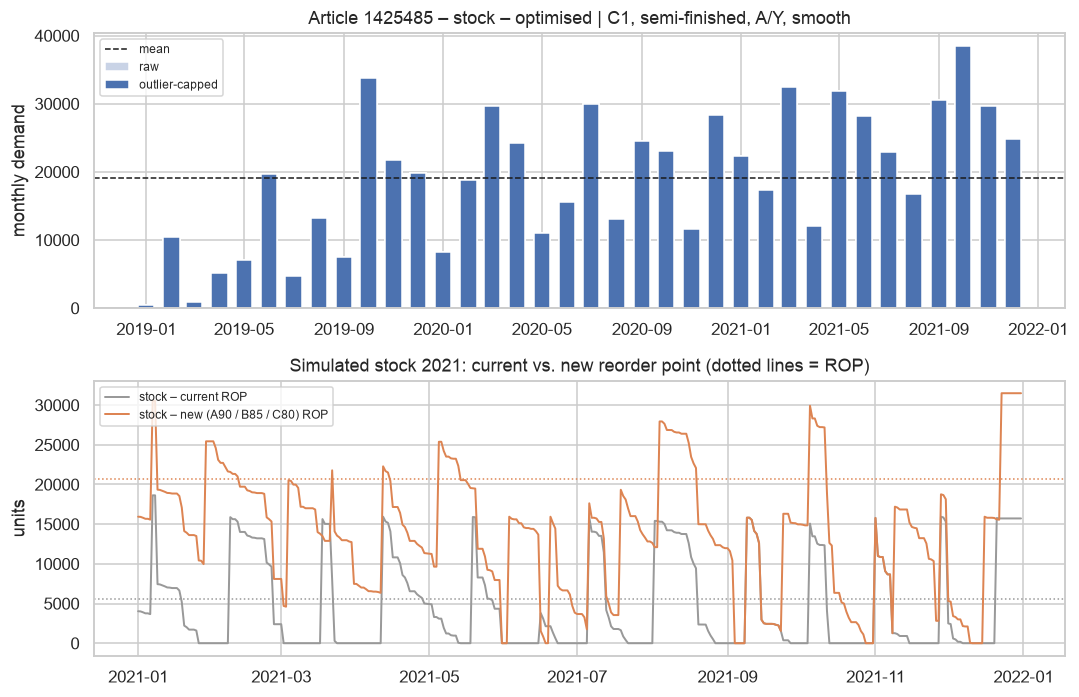

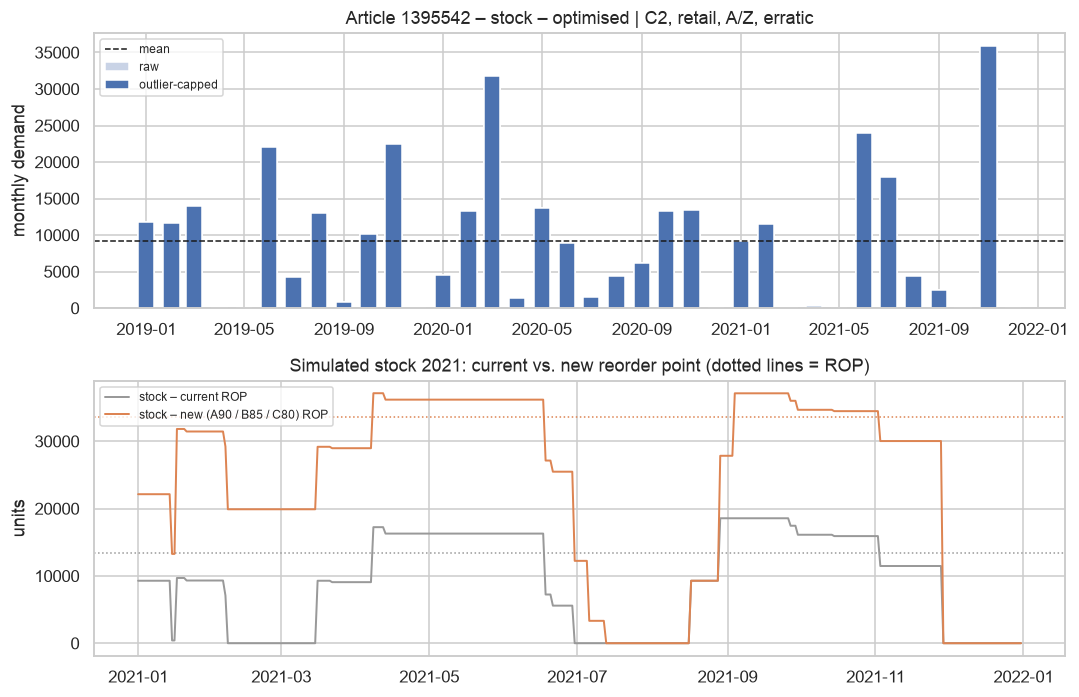

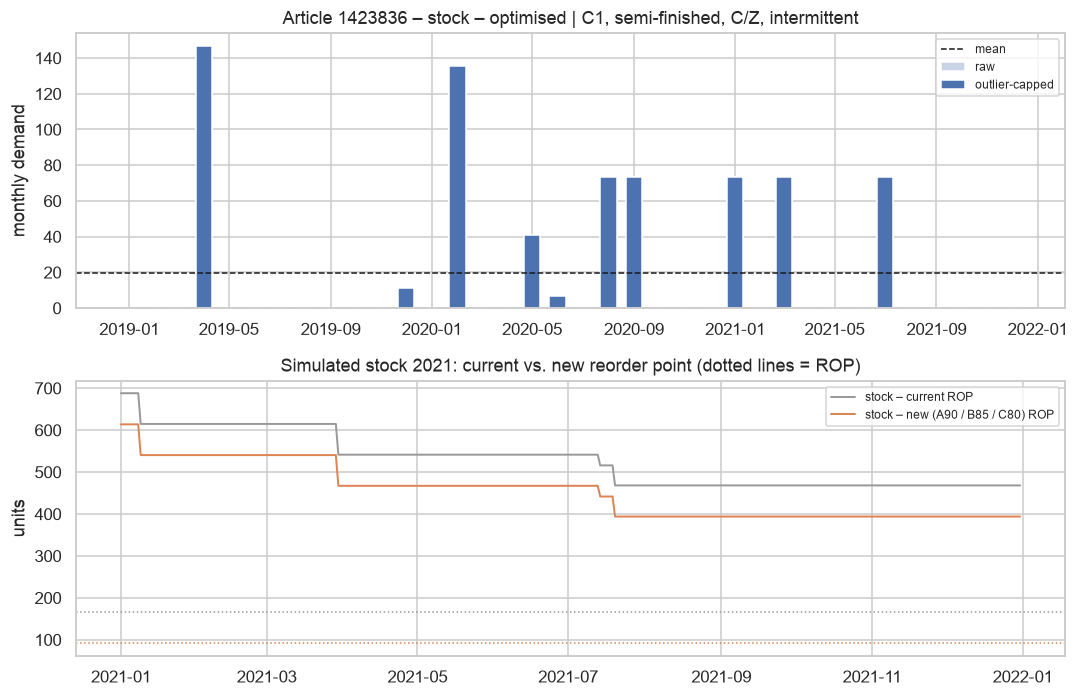

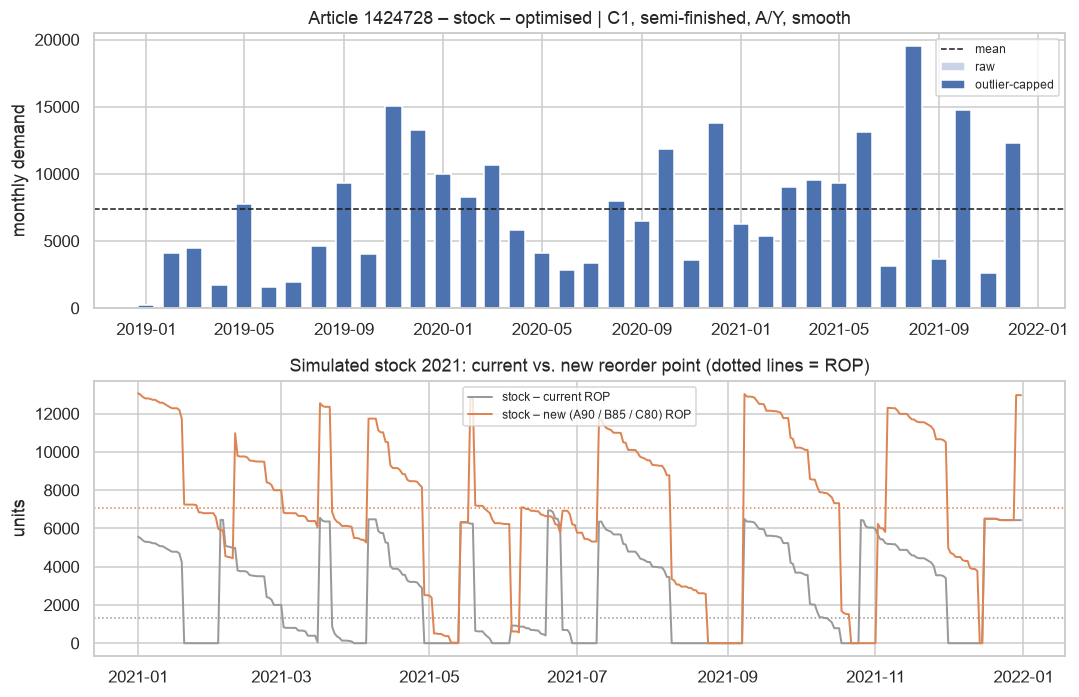

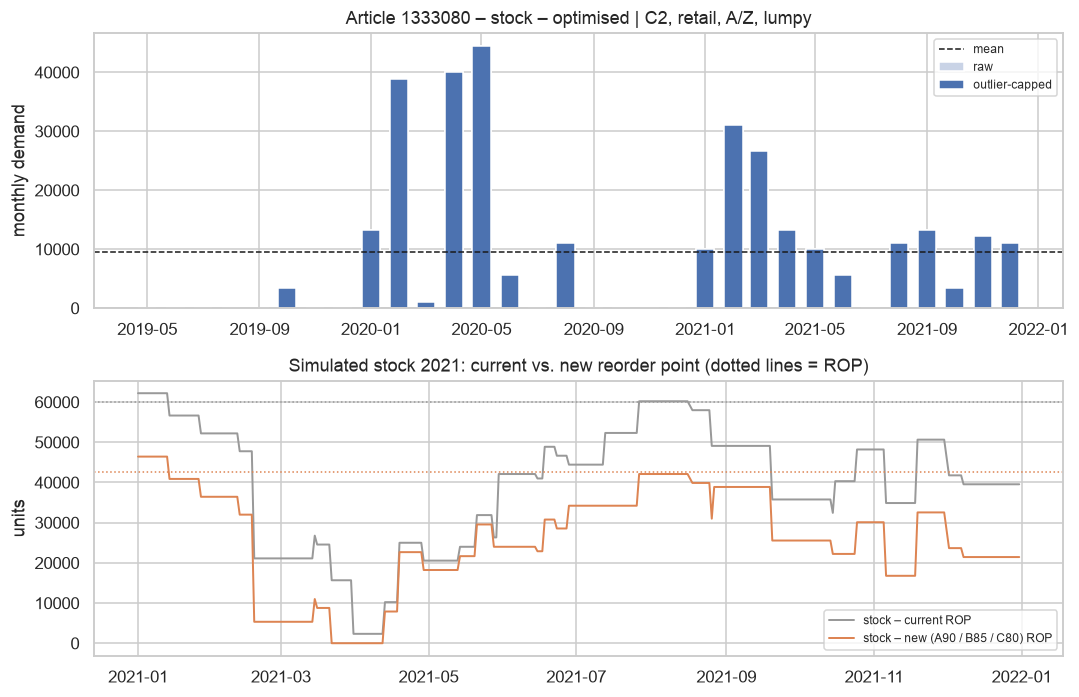

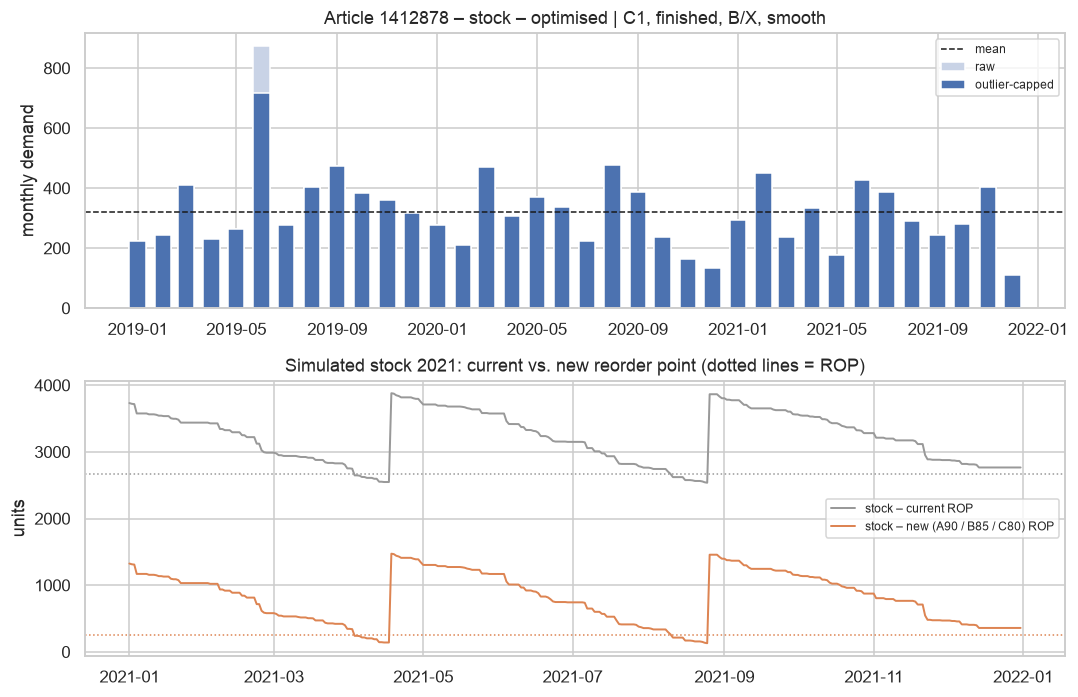

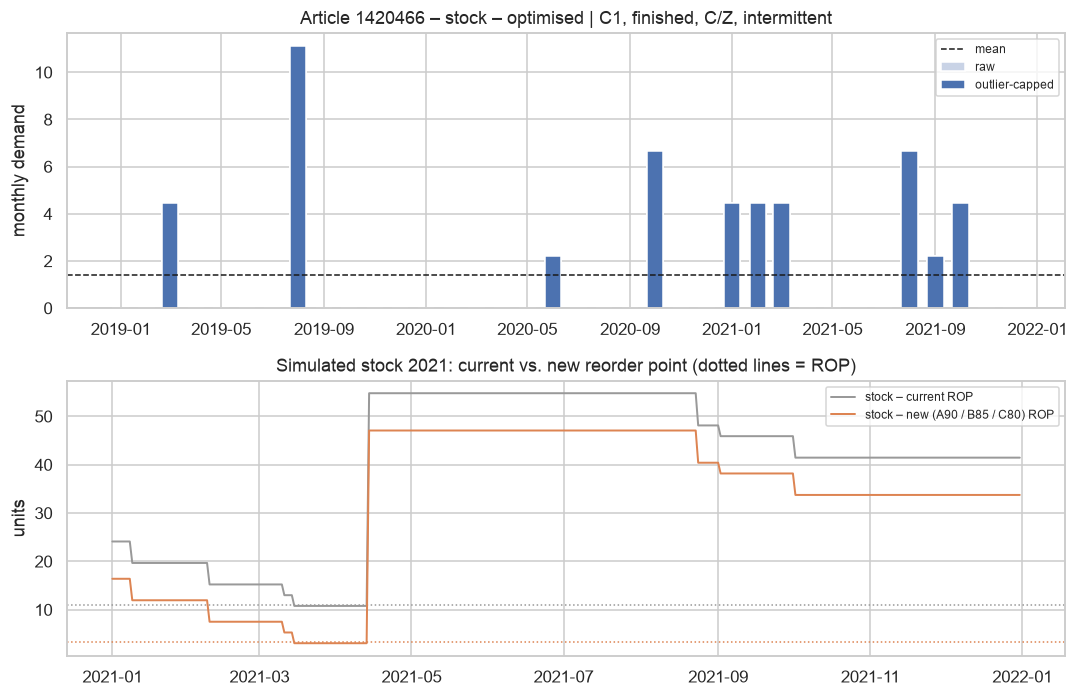

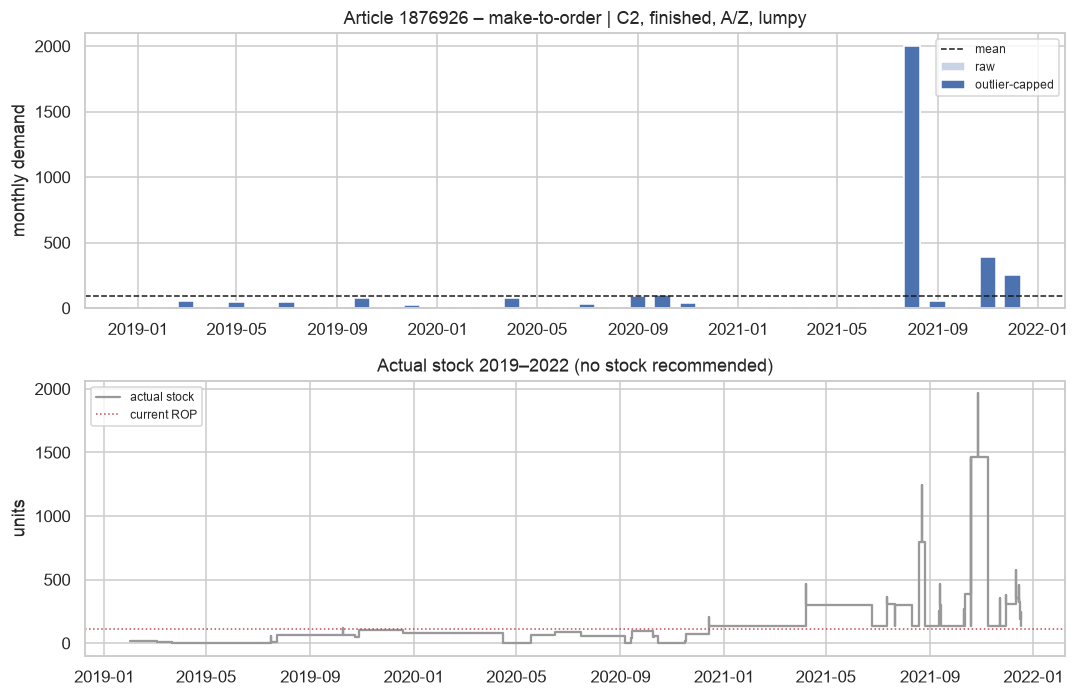

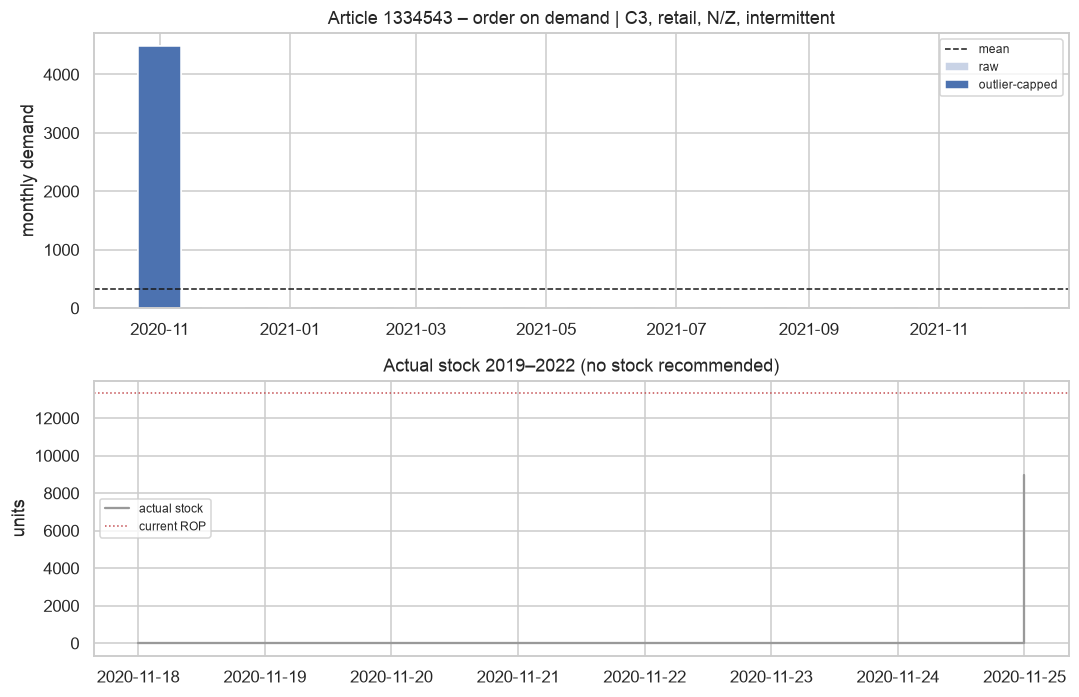

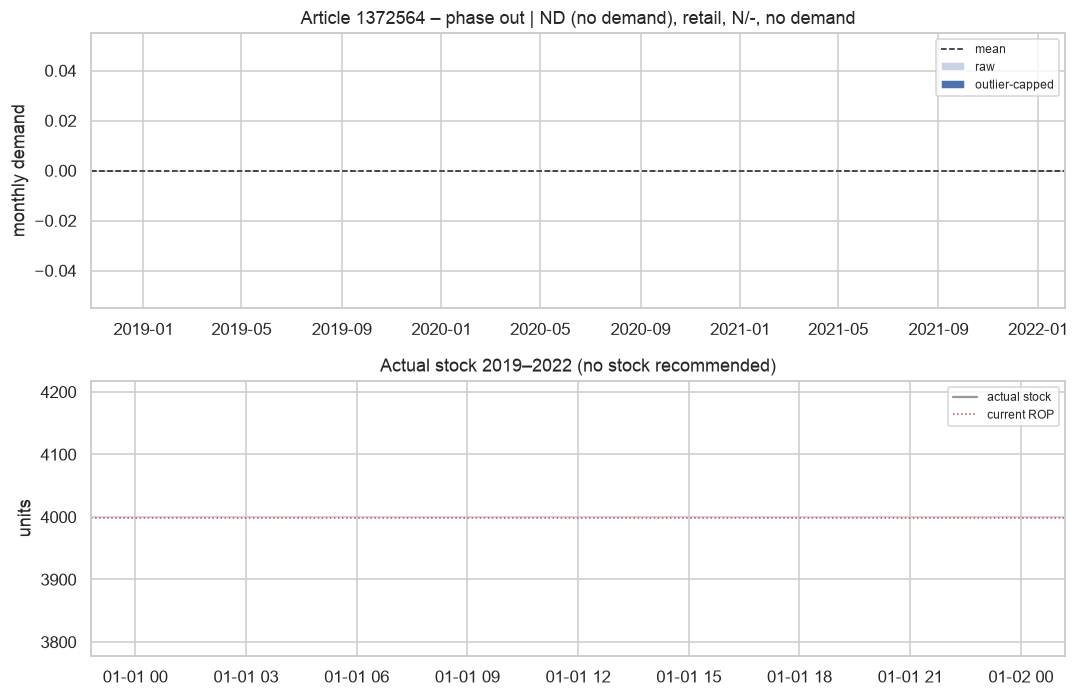

In [9]:
first_dates = pd.Timestamp(C.ANALYSIS_START)

def article_figure(a):
    fig, axes = plt.subplots(2, 1, figsize=(10, 6.5))
    x = dm[dm["article_nr"] == a]
    axes[0].bar(x["month"], x["demand_raw"], width=20, color="#C9D3E6", label="raw")
    axes[0].bar(x["month"], x["demand_capped"], width=20, color="#4C72B0", label="outlier-capped")
    axes[0].axhline(np.nan_to_num(art.at[a, "mean_monthly"]), ls="--", c="k", lw=1, label="mean")
    axes[0].set_title(f"Article {a} – {art.at[a, 'strategy']} | {art.at[a, 'cluster']}, {art.at[a, 'product_type']}, "
                      f"{art.at[a, 'abc']}/{art.at[a, 'xyz']}, {art.at[a, 'pattern']}")
    axes[0].set_ylabel("monthly demand"); axes[0].legend(fontsize=8)

    ax = axes[1]
    if stocked[a] and a in daily.index and a in has_hist and par.at[a, "q"] > 0:
        d = daily.loc[a].values
        for pol, rop, col in (("current", art.at[a, "current_rop"], "#999999"),
                              (f"new ({CHOSEN})", par_final.at[a, "rop_textbook"], "#DD8452")):
            stock, _ = simulate(d, rop, par.at[a, "q"], lt_sim[a])
            ax.plot(days[meas], stock[meas], color=col, lw=1.3, label=f"stock – {pol} ROP")
            ax.axhline(rop, color=col, ls=":", lw=1)
        ax.set_title("Simulated stock 2021: current vs. new reorder point (dotted lines = ROP)")
    else:
        h = tx[(tx["article_nr"] == a) & (tx["date"] >= first_dates)].sort_values(["date", "_row"], ascending=[True, False])
        ax.step(h["date"], h["stock_after"].clip(lower=0), where="post", color="#999999", label="actual stock")
        ax.axhline(art.at[a, "current_rop"], color="#C44E52", ls=":", lw=1, label="current ROP")
        ax.set_title("Actual stock 2019–2022 (no stock recommended)")
    ax.set_ylabel("units"); ax.legend(fontsize=8)
    plt.tight_layout()
    savefig(f"05_article_{a}")

for a in chosen:
    article_figure(a)

## 6. Export for the report appendix

In [10]:
export_cols = ["cluster", "strategy", "product_type", "abc", "xyz", "pattern", "lead_time", "moq", "last_direct_cost",
               "current_rop", "new_ss", "new_rop", "q", "lockup_12m", "new_lockup"]
art[export_cols].round(2).to_csv(C.TABLES / "05_recommendations_all_articles.csv")
ten.round(2).to_csv(C.TABLES / "05_ten_articles.csv")
with pd.ExcelWriter(C.TABLES / "05_recommendations.xlsx") as xw:
    ten.round(2).to_excel(xw, sheet_name="ten_articles")
    art[export_cols].round(2).to_excel(xw, sheet_name="all_articles")
    eff.round(0).to_excel(xw, sheet_name="capital_effect")
    agg.round(3).to_excel(xw, sheet_name="backtest")
    frontier.round(3).to_excel(xw, sheet_name="frontier")
log("Exported", "05_recommendations.xlsx, 05_recommendations_all_articles.csv, 05_ten_articles.csv")

out_file = C.TABLES / "05_recommendation_summary.txt"
out_file.write_text("\n".join(summary), encoding="utf-8")
print(f"Summary written to {out_file} – share this file.")


=== Exported ===
05_recommendations.xlsx, 05_recommendations_all_articles.csv, 05_ten_articles.csv
Summary written to /Users/nikolaosgeorgantopoulos/Repositories/inventory-optimization/outputs/tables/05_recommendation_summary.txt – share this file.
